# Fase D – Comunità multilayer sovrapposte (RQ2)

**Domanda:** esistono gruppi di wallet che scambiano in entrambi i mercati, e cosa si scambiano?

Le comunità della fase C sono calcolate in ogni mercato separatamente, e confrontarle trova solo i gruppi con gli stessi wallet nei due mercati. Qui le comunità si cercano **sui due mercati insieme**, e un wallet può stare in **più comunità** (overlapping community detection), come una persona che fa parte di più gruppi.

**Metodo (ego-splitting):**
1. Per ogni wallet si guardano le sue controparti, in entrambi i mercati. Quelle che scambiano anche tra loro vengono raggruppate con Leiden (risoluzione 1): ogni gruppo diventa un **personaggio** del wallet. Le controparti che non scambiano con nessun'altra vanno in un personaggio per mercato: solo username, solo numeri, entrambi.
2. Si cercano le comunità tra i personaggi con Leiden multiplex: username e numeri sono due livelli con **lo stesso peso**, ognuno con la sua modularità (risoluzione 1, seed 2026). Ci si ferma quando un passo migliora la qualità di meno di `ARRESTO`.
3. Un wallet appartiene a tutte le comunità dei suoi personaggi. Ogni passaggio tra due wallet sta dentro una comunità o va da una all'altra.

**Tipi di comunità**, dai passaggi interni:
* **di un solo mercato** se oltre il 92% dei passaggi interni è in quel mercato (la stessa soglia di P < 0,3 usata per i wallet in H2);
* altrimenti **inter-layer**: con gli **stessi wallet** se più di metà dei suoi wallet è attiva in entrambi i mercati, con **wallet diversi** altrimenti. Questi ultimi sono i **gruppi grandi**: wallet che scambiano username e wallet che scambiano numeri, tenuti insieme da wallet attivi in entrambi.

Rete: `senza_contratti`. Richiede `fase_b_reti.ipynb`.

## 0. Dati

In [1]:
import time
import numpy as np
import pandas as pd
import igraph as ig
import leidenalg as la
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from analisi_utils import *

stile()
V = 'senza_contratti'
RISOLUZIONE = 1.0
ARRESTO = 1e-4          # sotto questo miglioramento le comunità non cambiano più
SOGLIA_MERCATO = 0.92   # comunità di un solo mercato se oltre il 92% dei passaggi interni è lì
SOGLIA_STESSI = 0.5     # inter-layer con gli stessi wallet se più di metà dei wallet è attiva in entrambi i mercati
TOP = 12                # gruppi grandi mostrati nelle figure
MIN_NFT_CAT = 200       # categorie nella heatmap: almeno 200 NFT nel mercato, come nella fase C
TOP_Q = 0.01
A, B = LAYERS
cart = cartella_variante(V)
t0 = time.time()

L = {}
for l in LAYERS:
    e = pd.read_parquet(cart / f'edges_{FILE[l]}.parquet', columns=['sender', 'recipient', 'n_transfers'])
    L[l] = e[e.sender != e.recipient]
nodi = pd.Index(pd.unique(np.concatenate([np.concatenate([e.sender.to_numpy(), e.recipient.to_numpy()]) for e in L.values()])))
und = {}
for l, e in L.items():
    a, b = nodi.get_indexer(e.sender), nodi.get_indexer(e.recipient)
    und[l] = pd.DataFrame({'a': np.minimum(a, b), 'b': np.maximum(a, b), 'w': e.n_transfers.to_numpy(float)}).groupby(['a', 'b'], as_index=False).w.sum()
agg = pd.concat(und.values()).groupby(['a', 'b'], as_index=False).w.sum()
g = ig.Graph(n=len(nodi), edges=agg[['a', 'b']].to_numpy().tolist())

CENTR = pd.read_parquet(cart / 'centralita.parquet')
forza = {l: CENTR[(CENTR.layer == l) & (CENTR.grado > 0)].set_index('wallet').forza for l in LAYERS}
INF = {l: set(s.nlargest(int(round(TOP_Q * len(s)))).index) for l, s in forza.items()}
CORE = INF[A] & INF[B]
HUB = (INF[A] | INF[B]) - CORE
print(f'wallet con passaggi: {len(nodi):,} | coppie collegate: {g.ecount():,}'.replace(',', '.'))

wallet con passaggi: 410.545 | coppie collegate: 941.791


## 1. Personaggi

Le ego-net si ricavano dai triangoli: due controparti di un wallet sono collegate se scambiano tra loro, in qualunque mercato.

In [2]:
tri = np.array(g.list_triangles())
peso = pd.Series(agg.w.to_numpy(), index=pd.MultiIndex.from_arrays([agg.a, agg.b]))
EG = pd.concat([pd.DataFrame({'ego': tri[:, e], 'p': np.minimum(tri[:, p], tri[:, q]), 'q': np.maximum(tri[:, p], tri[:, q])})
                for e, p, q in [(0, 1, 2), (1, 0, 2), (2, 0, 1)]], ignore_index=True)
EG['w'] = peso.reindex(pd.MultiIndex.from_arrays([EG.p, EG.q])).to_numpy()

loc = []
for ego, d in EG.groupby('ego', sort=False):
    v = pd.Index(pd.unique(np.concatenate([d.p.to_numpy(), d.q.to_numpy()])))
    h = ig.Graph(n=len(v), edges=np.c_[v.get_indexer(d.p), v.get_indexer(d.q)].tolist(), edge_attrs={'weight': d.w.tolist()})
    memb = h.connected_components().membership if len(v) <= 3 else \
        la.find_partition(h, la.RBConfigurationVertexPartition, weights='weight', resolution_parameter=RISOLUZIONE, seed=SEED).membership
    loc.append(pd.DataFrame({'u': ego, 'v': v.to_numpy(), 'gruppo': memb}))
LOC = pd.concat(loc, ignore_index=True)

mercato = pd.concat([d[['a', 'b']].assign(**{l: True}) for l, d in und.items()]).groupby(['a', 'b']).max().fillna(False).reset_index()
mercato = pd.concat([mercato.set_axis(['u', 'v', A, B], axis=1), mercato.set_axis(['v', 'u', A, B], axis=1)], ignore_index=True)
mezzi = mercato.merge(LOC, on=['u', 'v'], how='left')
resto = np.where(mezzi[A] & mezzi[B], -3, np.where(mezzi[A], -1, -2))   # controparti sparse: un personaggio per mercato
mezzi['gruppo'] = mezzi.gruppo.fillna(pd.Series(resto, index=mezzi.index)).astype(int)
mezzi['persona'], uniche = pd.factorize(pd.MultiIndex.from_arrays([mezzi.u, mezzi.gruppo]))
N_PERS = len(uniche)
pers_wallet = np.array([k[0] for k in uniche])
chiave = pd.Series(mezzi.persona.to_numpy(), index=pd.MultiIndex.from_arrays([mezzi.u, mezzi.v]))
divisi = (pd.Series(pers_wallet).value_counts() > 1).sum()
print(f'triangoli: {len(tri):,} | personaggi: {N_PERS:,} | wallet con più personaggi: {divisi:,} | {time.time() - t0:.0f} s'.replace(',', '.'))

triangoli: 522.156 | personaggi: 571.281 | wallet con più personaggi: 81.931 | 74 s


## 2. Comunità tra i personaggi

In [3]:
GP, ARCHI = {}, {}
for l, d in und.items():
    pa = chiave.reindex(pd.MultiIndex.from_arrays([d.a, d.b])).to_numpy()
    pb = chiave.reindex(pd.MultiIndex.from_arrays([d.b, d.a])).to_numpy()
    ARCHI[l] = pd.DataFrame({'a': d.a, 'b': d.b, 'pa': pa, 'pb': pb, 'w': d.w})
    GP[l] = ig.Graph(n=N_PERS, edges=np.c_[pa, pb].tolist(), edge_attrs={'weight': d.w.tolist()})
tot = {l: sum(GP[l].es['weight']) for l in LAYERS}
parti = [la.RBConfigurationVertexPartition(GP[l], weights='weight', resolution_parameter=RISOLUZIONE) for l in LAYERS]
opt = la.Optimiser()
opt.set_rng_seed(SEED)
passi, guadagno = 0, np.inf
while guadagno > ARRESTO:
    guadagno = opt.optimise_partition_multiplex(parti, layer_weights=[1 / tot[l] for l in LAYERS], n_iterations=1)
    passi += 1
comm = np.array(parti[0].membership)
PERS = pd.DataFrame({'persona': np.arange(N_PERS), 'wallet': nodi[pers_wallet], 'comunita': comm})
PERS.to_parquet(cart / 'multilayer_personaggi.parquet')
for l in LAYERS:
    x = ARCHI[l]
    x['ca'], x['cb'] = comm[x.pa], comm[x.pb]
    x['wa'], x['wb'] = nodi[x.a], nodi[x.b]
    x[['wa', 'wb', 'w', 'ca', 'cb']].to_parquet(cart / f'multilayer_archi_{FILE[l]}.parquet')
print(f'{passi} passi | comunità: {len(set(comm)):,} | modularità: {NOME[A]} {parti[0].modularity:.2f}, {NOME[B]} {parti[1].modularity:.2f} | {time.time() - t0:.0f} s'.replace(',', '.'))

13 passi | comunità: 36.846 | modularità: Username 0.86. Numeri 0.76 | 466 s


## 3. Tipi di comunità

Per ogni comunità: passaggi interni in ogni mercato, wallet attivi negli username, nei numeri e in entrambi (con almeno un passaggio interno). Sotto, quante comunità ha ogni wallet e dove finiscono le 74 comunità speculari trovate confrontando le partizioni della fase C.

In [4]:
interni = pd.concat([pd.concat([ARCHI[l].loc[ARCHI[l].ca == ARCHI[l].cb, ['ca', 'wa', 'w']].set_axis(['c', 'wallet', 'w'], axis=1),
                                ARCHI[l].loc[ARCHI[l].ca == ARCHI[l].cb, ['ca', 'wb', 'w']].set_axis(['c', 'wallet', 'w'], axis=1)]).assign(layer=l) for l in LAYERS])
COM = pd.DataFrame({l: ARCHI[l][ARCHI[l].ca == ARCHI[l].cb].groupby('ca').w.sum() for l in LAYERS}).fillna(0)
COM.columns = [f'passaggi {NOME[l].lower()}' for l in LAYERS]
COM['quota username'] = COM.iloc[:, 0] / COM.iloc[:, :2].sum(axis=1)
attivi_c = {l: interni[interni.layer == l].drop_duplicates(['c', 'wallet']) for l in LAYERS}
COM['wallet username'] = attivi_c[A].groupby('c').size().reindex(COM.index, fill_value=0)
COM['wallet numeri'] = attivi_c[B].groupby('c').size().reindex(COM.index, fill_value=0)
COM['wallet in entrambi'] = attivi_c[A].merge(attivi_c[B], on=['c', 'wallet']).groupby('c').size().reindex(COM.index, fill_value=0)
COM['wallet'] = COM['wallet username'] + COM['wallet numeri'] - COM['wallet in entrambi']
COM['quota wallet in entrambi'] = COM['wallet in entrambi'] / COM.wallet
COM['tipo'] = np.select([COM['quota username'] > SOGLIA_MERCATO, COM['quota username'] < 1 - SOGLIA_MERCATO, COM['quota wallet in entrambi'] > SOGLIA_STESSI],
                        ['solo username', 'solo numeri', 'inter-layer, stessi wallet'], 'inter-layer, wallet diversi')
membri = interni.drop_duplicates(['c', 'wallet'])
COM['core'] = membri[membri.wallet.isin(list(CORE))].groupby('c').size().reindex(COM.index, fill_value=0)
COM['hub specialisti'] = membri[membri.wallet.isin(list(HUB))].groupby('c').size().reindex(COM.index, fill_value=0)
COM.index.name = 'comunita'
salva_tabella(COM, 'd_multilayer_comunita')

TIPI = ['solo username', 'solo numeri', 'inter-layer, stessi wallet', 'inter-layer, wallet diversi']
riassunto = COM.groupby('tipo').agg(comunita=('wallet', 'size'), wallet_mediani=('wallet', 'median'), wallet_max=('wallet', 'max'),
                                    passaggi_username=(COM.columns[0], 'sum'), passaggi_numeri=(COM.columns[1], 'sum'), core=('core', 'sum')).reindex(TIPI)
for l, col in zip(LAYERS, ['passaggi_username', 'passaggi_numeri']):
    riassunto[f'quota dei passaggi interni, {NOME[l].lower()}'] = riassunto[col] / riassunto[col].sum()
riassunto['coppie (2 wallet)'] = COM[COM.wallet == 2].groupby('tipo').size().reindex(TIPI, fill_value=0)
salva_tabella(riassunto, 'd_multilayer_tipi')
display(riassunto)

per_wallet = PERS.drop_duplicates(['wallet', 'comunita']).groupby('wallet').size()
gruppo_w = pd.Series('altri wallet', index=per_wallet.index)
gruppo_w[per_wallet.index.isin(list(HUB))] = 'hub specialisti'
gruppo_w[per_wallet.index.isin(list(CORE))] = 'core'
quante = per_wallet.groupby(gruppo_w).agg(wallet='size', mediana='median', massimo='max')
quante['in più comunità'] = per_wallet.gt(1).groupby(gruppo_w).mean()
display(quante)

speculari = TABELLE / 'd_comunita_speculari.csv'
if speculari.exists():
    comu = {l: pd.read_parquet(cart / f'comunita_{FILE[l]}.parquet').set_index('wallet').comunita for l in LAYERS}
    S = comu[A].index.intersection(comu[B].index)
    mem = pd.DataFrame({'U': comu[A][S], 'N': comu[B][S]})
    trovate = []
    for r in pd.read_csv(speculari).itertuples():
        M = set(mem.index[(mem.U == r.U) & (mem.N == r.N)])
        x = pd.concat([ARCHI[l][ARCHI[l].wa.isin(M) & ARCHI[l].wb.isin(M)] for l in LAYERS])
        dentro = x[x.ca == x.cb].groupby('ca').w.sum()
        c = dentro.idxmax() if len(dentro) else None
        trovate.append({'tipo speculare': r.tipo, 'tipo trovato': COM.tipo.get(c, 'nessuna'), 'quota dei passaggi in una comunità': dentro.max() / x.w.sum() if len(dentro) else 0,
                        'al massimo il doppio dei wallet': COM.wallet.get(c, np.inf) <= 2 * len(M)})
    trovate = pd.DataFrame(trovate)
    print('Le 74 comunità speculari:'); display(pd.crosstab(trovate['tipo speculare'], trovate['tipo trovato']))
    print(f"passaggi in una sola comunità (mediana): {trovate['quota dei passaggi in una comunità'].median():.0%} | "
          f"in una comunità al massimo doppia: {trovate['al massimo il doppio dei wallet'].sum()} su {len(trovate)}")

,comunita,wallet_mediani,wallet_max,passaggi_username,passaggi_numeri,core,"quota dei passaggi interni, username","quota dei passaggi interni, numeri",coppie (2 wallet)
tipo,,,,,,,,,
solo username,25785,3,41084,1.133e+06,5197,539,0.8128,0.009159,7561
solo numeri,5627,3,39732,1310,2.925e+05,496,0.0009402,0.5155,1736
"inter-layer, stessi wallet",5079,2,55,4.95e+04,3.56e+04,253,0.03553,0.06275,2672
"inter-layer, wallet diversi",355,6,19236,2.099e+05,2.341e+05,678,0.1507,0.4126,0


,wallet,mediana,massimo,in più comunità
altri wallet,406369,1,36,0.19
core,234,7,124,1
hub specialisti,3942,4,263,0.9302


Le 74 comunità speculari:


tipo trovato,"inter-layer, stessi wallet",solo numeri,solo username
tipo speculare,,,
catena,9,0,0
coppia,46,1,1
gruppo chiuso,17,0,0


passaggi in una sola comunità (mediana): 100% | in una comunità al massimo doppia: 74 su 74


## 4. I gruppi grandi: chi c'è dentro e cosa si scambiano

I **gruppi grandi** sono le comunità inter-layer con wallet diversi. Per ognuno, solo i passaggi **interni**:
* composizione: wallet attivi solo negli username, solo nei numeri, in entrambi; core e hub specialisti;
* passaggi, NFT distinti, **quota di vendite** e **prezzo mediano** delle vendite in ogni mercato (le mediane non risentono dei prezzi anomali);
* periodo: primo e ultimo passaggio interno;
* quota dei passaggi che toccano un wallet attivo in entrambi i mercati (i **ponti**).

In [5]:
EV = pd.read_parquet(cart / 'transfer_events.parquet', columns=['layer', 'nft', 'src', 'dst', 'ts', 'tipo_riga', 'is_purchase', 'price_ton'])
EV = EV[(EV.tipo_riga == 'A -> B') & (EV.src != EV.dst)].drop(columns='tipo_riga')
EV['k1'], EV['k2'] = np.minimum(EV.src, EV.dst), np.maximum(EV.src, EV.dst)
PASS = []
for l in LAYERS:
    x = ARCHI[l][['wa', 'wb', 'ca', 'cb']].copy()
    x['k1'], x['k2'] = np.minimum(x.wa, x.wb), np.maximum(x.wa, x.wb)
    PASS.append(EV[EV.layer == l].merge(x[['k1', 'k2', 'ca', 'cb']], on=['k1', 'k2'], how='left'))
PASS = pd.concat(PASS, ignore_index=True)
del EV
assert PASS.ca.notna().all()

GRANDI = COM[COM.tipo == 'inter-layer, wallet diversi'].sort_values('wallet', ascending=False).copy()
GRANDI['gruppo'] = [f'G{i + 1}' for i in range(len(GRANDI))]
nome_g = GRANDI.gruppo
dentro = PASS[(PASS.ca == PASS.cb) & PASS.ca.isin(GRANDI.index)]
ponti = attivi_c[A].merge(attivi_c[B], on=['c', 'wallet'])[['c', 'wallet']]
ponti_set = set(zip(ponti.c, ponti.wallet))
dentro = dentro.assign(ponte=[(c, s) in ponti_set or (c, d) in ponti_set for c, s, d in zip(dentro.ca, dentro.src, dentro.dst)])
righe = []
for c, r in GRANDI.iterrows():
    d = dentro[dentro.ca == c]
    riga = {'gruppo': r.gruppo, 'wallet': int(r.wallet), 'solo username': int(r['wallet username'] - r['wallet in entrambi']),
            'solo numeri': int(r['wallet numeri'] - r['wallet in entrambi']), 'in entrambi': int(r['wallet in entrambi']),
            'core': int(r.core), 'hub specialisti': int(r['hub specialisti'])}
    for l in LAYERS:
        x = d[d.layer == l]
        n = NOME[l].lower()
        riga.update({f'passaggi {n}': len(x), f'NFT {n}': x.nft.nunique(), f'quota vendite {n}': x.is_purchase.mean() if len(x) else np.nan,
                     f'prezzo mediano {n} (TON)': x.loc[x.is_purchase, 'price_ton'].median()})
    riga.update({'quota dei passaggi con un ponte': d.ponte.mean(), 'primo': d.ts.min(), 'ultimo': d.ts.max(),
                 'anno mediano': d.ts.dt.year.median()})
    righe.append(riga)
PROFILI = pd.DataFrame(righe).set_index('gruppo')
salva_tabella(PROFILI, 'd_multilayer_gruppi_grandi')
print(f"gruppi grandi: {len(GRANDI)} | wallet: {int(GRANDI.wallet.sum()):,} | core dentro almeno un gruppo grande: "
      f"{membri[membri.c.isin(GRANDI.index) & membri.wallet.isin(list(CORE))].wallet.nunique()} su {len(CORE)}".replace(',', '.'))
leggibile(PROFILI.head(TOP))

gruppi grandi: 355 | wallet: 41.857 | core dentro almeno un gruppo grande: 228 su 234


,wallet,solo username,solo numeri,in entrambi,core,hub specialisti,passaggi username,NFT username,quota vendite username,prezzo mediano username (TON),passaggi numeri,NFT numeri,quota vendite numeri,prezzo mediano numeri (TON),quota dei passaggi con un ponte,primo,ultimo,anno mediano
gruppo,,,,,,,,,,,,,,,,,,
G1,19.236,9.254,6.688,3.294,139,1.440,85.914,52.020,0.687,7,68.079,32.558,0.627,403,0.821,2022-11-28 22:13:20+00:00,2026-10-22 01:23:23+00:00,2.025
G2,6.528,595,4.859,1.074,65,487,9.092,6.584,0.553,8,48.977,30.203,0.903,39,0.653,2022-11-16 21:55:16+00:00,2026-10-20 09:21:27+00:00,2.023
G3,2.916,374,1.655,887,88,367,9.236,4.969,0.0257,25,28.932,11.942,0.131,1.138,0.891,2022-12-25 16:40:23+00:00,2026-10-21 22:19:03+00:00,2.026
G4,2.586,1.880,55,651,7,179,22.286,8.732,0.0528,113,2.528,1.053,0.0202,930,0.822,2022-11-23 19:27:25+00:00,2026-10-21 21:40:16+00:00,2.025
G5,1.710,1.059,206,445,45,268,16.298,7.676,0.048,20,6.259,2.094,0.00399,1.801,0.766,2022-12-14 01:38:43+00:00,2026-10-21 12:21:44+00:00,2.026
G6,1.457,522,381,554,61,186,11.472,5.801,0.0258,12,10.032,4.168,0.0189,177,0.919,2022-11-21 21:13:44+00:00,2026-10-20 12:20:20+00:00,2.024
G7,865,228,253,384,53,179,9.737,4.287,0.0109,135,8.633,4.280,0.0137,140,0.958,2022-12-13 12:13:04+00:00,2026-10-21 13:33:10+00:00,2.025
G8,833,70,591,172,23,77,3.121,1.937,0.0154,45,12.446,7.064,0.0199,174,0.531,2022-11-19 05:29:47+00:00,2026-10-20 15:06:01+00:00,2.025
G9,549,449,28,72,3,93,4.477,3.570,0.395,7,491,227,0.057,315,0.421,2024-05-02 12:38:02+00:00,2026-10-19 10:36:12+00:00,2.026


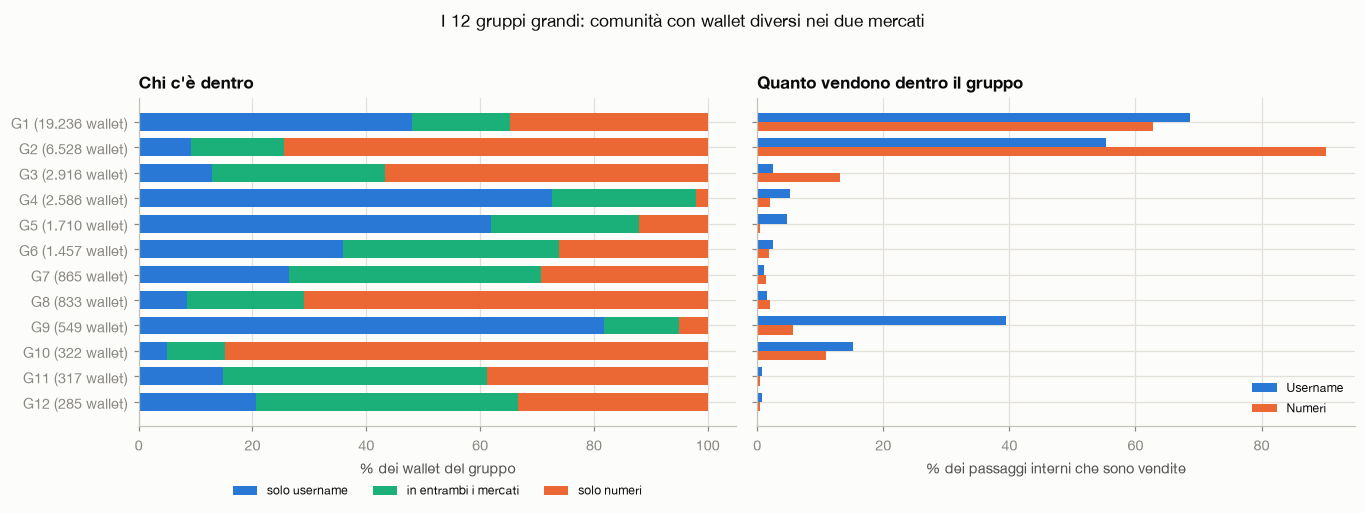

In [6]:
top = PROFILI.head(TOP)
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6), sharey=True)
y = np.arange(len(top))[::-1]
sinistra = np.zeros(len(top))
for col, colore, nome in [('solo username', COLORI[A], 'solo username'), ('in entrambi', COLORI['cross'], 'in entrambi i mercati'), ('solo numeri', COLORI[B], 'solo numeri')]:
    q = top[col] / top.wallet
    axes[0].barh(y, q * 100, left=sinistra * 100, color=colore, label=nome, height=0.7)
    sinistra += q
axes[0].set_yticks(y, [f'{g} ({w:,} wallet)'.replace(',', '.') for g, w in zip(top.index, top.wallet)])
axes[0].set_xlabel('% dei wallet del gruppo')
axes[0].set_title('Chi c\'è dentro')
axes[0].legend(loc='upper center', bbox_to_anchor=(0.5, -0.14), ncol=3, fontsize=8)
for k, (l, sposta) in enumerate([(A, 0.18), (B, -0.18)]):
    axes[1].barh(y + sposta, top[f'quota vendite {NOME[l].lower()}'] * 100, height=0.36, color=COLORI[l], label=NOME[l])
axes[1].set_xlabel('% dei passaggi interni che sono vendite')
axes[1].set_title('Quanto vendono dentro il gruppo')
axes[1].legend(loc='lower right', fontsize=8)
fig.suptitle(f'I {TOP} gruppi grandi: comunità con wallet diversi nei due mercati', y=1.02)
fig.tight_layout()
salva_figura(fig, 'd_multilayer_gruppi_grandi')
plt.show()

### Che categorie si scambiano

Per ogni gruppo grande e ogni mercato: gli NFT distinti dei passaggi interni, confrontati con gli NFT del mercato con almeno un passaggio (la stessa base della fase C). Il colore è il log2 del rapporto tra le due quote: 0 = come nel mercato, +1 = il doppio, −1 = la metà; la scala è tagliata a ±3, e −3 vuol dire anche "assente". Categorie con almeno 200 NFT nel mercato.

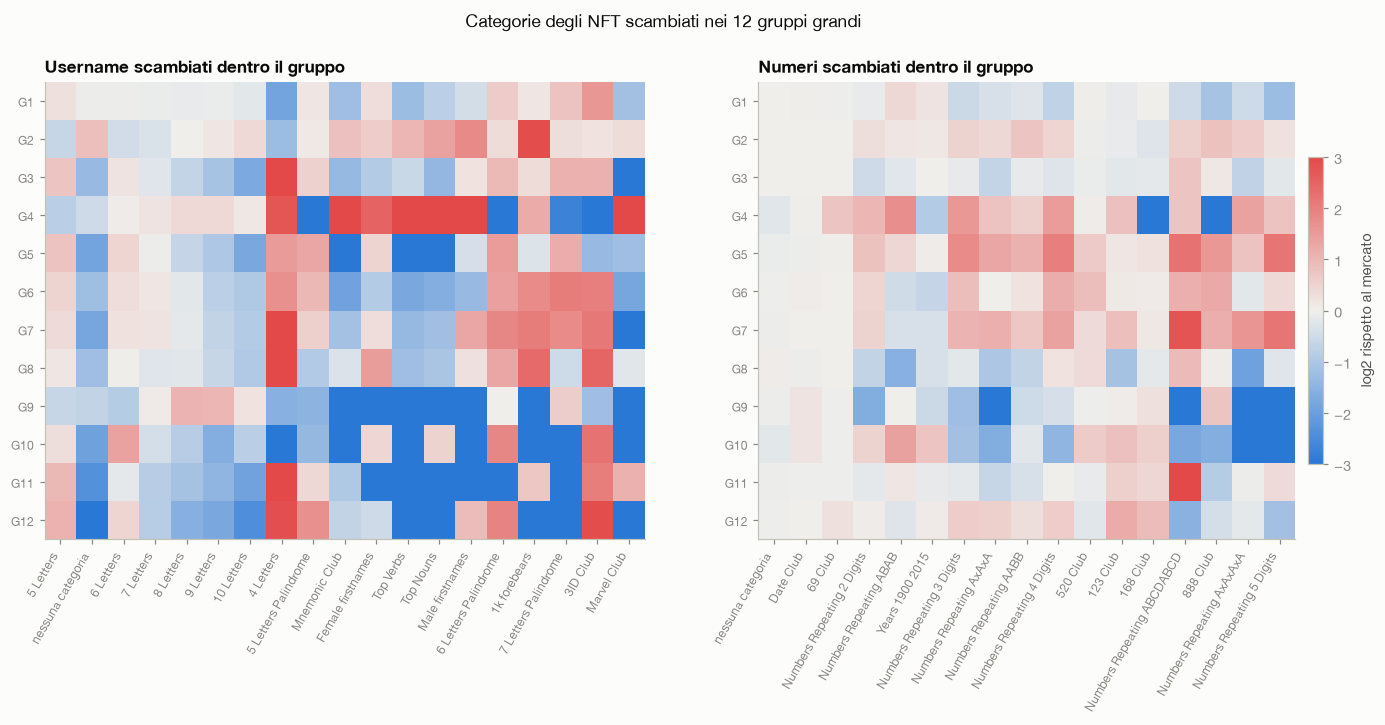

Categorie almeno doppie rispetto al mercato, con almeno 20 NFT, nei gruppi mostrati:


,gruppo,layer,categoria,NFT con categoria,quota,quota nel mercato,log2 arricchimento
23,G1,Username,9 Letters Palindrome,43,0.0008266,0.0002646,1.643
17,G1,Username,3ID Club,101,0.001942,0.0006474,1.585
25,G1,Username,8 Letters Palindrome,23,0.0004421,0.000167,1.405
23749,G10,Numeri,Numbers Repeating ABAB,163,0.0682,0.02614,1.383
596,G10,Username,6 Letters,273,0.4143,0.1612,1.362
667,G11,Username,4 Letters,118,0.1547,0.009857,3.972
23793,G11,Numeri,Numbers Repeating ABCDABCD,33,0.02337,0.002835,3.043
733,G12,Username,4 Letters,45,0.07188,0.009857,2.866
726,G12,Username,5 Letters,332,0.5304,0.2479,1.097
81,G2,Username,1k forebears,39,0.005923,0.0007938,2.9


In [7]:
CAT = pd.read_parquet(DATI / 'fragment_final.parquet', columns=['nft', 'categories']).drop_duplicates('nft').set_index('nft').categories
righe = []
for l in LAYERS:
    base = pd.Index(PASS.loc[PASS.layer == l, 'nft'].unique())
    q_base = CAT.reindex(base).explode().value_counts()
    n_base = len(base)
    for c, g_ in nome_g.items():
        nft = dentro.loc[(dentro.ca == c) & (dentro.layer == l), 'nft'].unique()
        if len(nft) == 0:
            continue
        conta = CAT.reindex(nft).explode().value_counts()
        for cat, n_cat in q_base.items():
            k = conta.get(cat, 0)
            righe.append({'gruppo': g_, 'layer': NOME[l], 'categoria': cat, 'NFT del gruppo': len(nft), 'NFT con categoria': k,
                          'quota': k / len(nft), 'quota nel mercato': n_cat / n_base, 'NFT categoria nel mercato': n_cat})
ARR = pd.DataFrame(righe)
with np.errstate(divide='ignore'):
    ARR['log2 arricchimento'] = np.log2(ARR.quota / ARR['quota nel mercato'])
salva_tabella(ARR, 'd_multilayer_categorie', index=False)

blu_rosso = LinearSegmentedColormap.from_list('bluerosso', ['#2a78d6', '#f0efec', '#e34948'])
ordine_g = list(PROFILI.head(TOP).index)
fig, axes = plt.subplots(1, 2, figsize=(15, 5.4), gridspec_kw={'width_ratios': [19, 17]})
for ax, l in zip(axes, LAYERS):
    r = ARR[(ARR.layer == NOME[l]) & (ARR['NFT categoria nel mercato'] >= MIN_NFT_CAT) & ARR.gruppo.isin(ordine_g)]
    colonne = r.drop_duplicates('categoria').sort_values('NFT categoria nel mercato', ascending=False).categoria.tolist()
    mat = r.pivot(index='gruppo', columns='categoria', values='log2 arricchimento').reindex(index=ordine_g, columns=colonne)
    im = ax.imshow(mat.clip(-3, 3).fillna(-3), vmin=-3, vmax=3, cmap=blu_rosso, aspect='auto')
    ax.set_xticks(range(len(colonne)), [c.replace('No_Categories', 'nessuna categoria') for c in colonne], rotation=60, ha='right', fontsize=8)
    ax.set_yticks(range(len(ordine_g)), ordine_g, fontsize=8)
    ax.grid(False)
    ax.set_title(f'{NOME[l]} scambiati dentro il gruppo')
fig.colorbar(im, ax=axes, fraction=0.012, pad=0.01, label='log2 rispetto al mercato')
fig.suptitle(f'Categorie degli NFT scambiati nei {TOP} gruppi grandi', y=1.0)
salva_figura(fig, 'd_multilayer_categorie')
plt.show()

forti = ARR[(ARR['NFT con categoria'] >= 20) & (ARR.categoria != 'No_Categories') & (ARR['log2 arricchimento'] >= 1)]
print('Categorie almeno doppie rispetto al mercato, con almeno 20 NFT, nei gruppi mostrati:')
display(forti[forti.gruppo.isin(ordine_g)].sort_values(['gruppo', 'log2 arricchimento'], ascending=[True, False])
        .groupby(['gruppo', 'layer']).head(3)[['gruppo', 'layer', 'categoria', 'NFT con categoria', 'quota', 'quota nel mercato', 'log2 arricchimento']])

### La mappa dei gruppi grandi

Ogni cerchio è un gruppo grande con almeno 20 wallet: in orizzontale la quota dei passaggi interni che sono vendite, in verticale la quota di NFT rari tra quelli scambiati nel gruppo (un NFT è raro se ha una categoria presente in meno dell'1% degli NFT del suo mercato, `No_Categories` esclusa). La grandezza è il numero di wallet, il colore quanti wallet del core contiene. Le linee tratteggiate sono i valori di tutto il mercato.

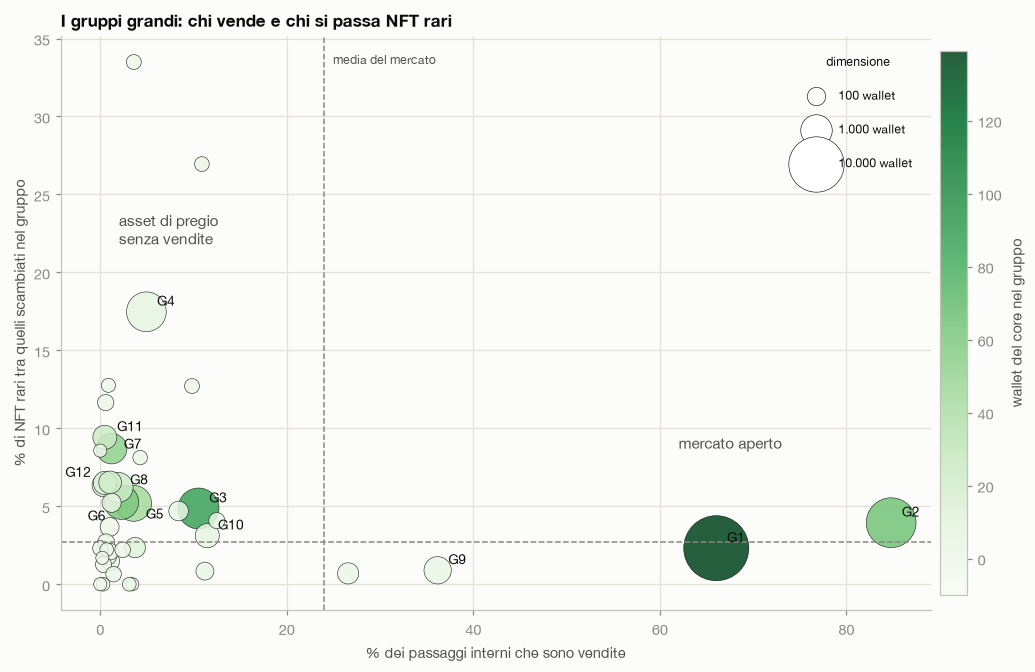

mercato: 24% di vendite, 2.7% di NFT rari | gruppi a sinistra della media vendite e sopra la media rari: 22 su 42


In [8]:
base_rari = {}
for l in LAYERS:
    base = pd.Index(PASS.loc[PASS.layer == l, 'nft'].unique())
    q = CAT.reindex(base).explode().value_counts() / len(base)
    rare = set(q[(q < 0.01) & (q.index != 'No_Categories')].index)
    base_rari[l] = CAT.reindex(base).apply(lambda c: bool(set(c) & rare))
raro = pd.concat(base_rari.values())
MAPPA = dentro.groupby('ca').agg(vendite=('is_purchase', 'mean'), passaggi=('nft', 'size'))
MAPPA['rari'] = dentro.drop_duplicates(['ca', 'nft']).nft.map(raro).groupby(dentro.drop_duplicates(['ca', 'nft']).ca).mean()
MAPPA = MAPPA.join(GRANDI[['wallet', 'core', 'gruppo']])
MAPPA = MAPPA[MAPPA.wallet >= 20]
media_vendite, media_rari = PASS.is_purchase.mean(), raro.mean()
salva_tabella(MAPPA.set_index('gruppo'), 'd_multilayer_mappa')

fig, ax = plt.subplots(figsize=(9.5, 6.2))
dim = lambda w: 15 + 1800 * np.sqrt(w / MAPPA.wallet.max())
sc = ax.scatter(MAPPA.vendite * 100, MAPPA.rari * 100, s=dim(MAPPA.wallet), c=MAPPA.core, cmap='Greens', vmin=-10, vmax=MAPPA.core.max(),
                edgecolors=INK, linewidths=0.4, alpha=0.85)
ax.axvline(media_vendite * 100, color=GRIGIO, linestyle='--', linewidth=1)
ax.axhline(media_rari * 100, color=GRIGIO, linestyle='--', linewidth=1)
sposta = {'G5': (8, -10), 'G6': (-22, -12), 'G8': (8, 2), 'G12': (-26, 4), 'G7': (8, 0), 'G11': (8, 4)}
for _, r in MAPPA[MAPPA.gruppo.isin([f'G{i}' for i in range(1, TOP + 1)])].iterrows():
    ax.annotate(r.gruppo, (r.vendite * 100, r.rari * 100), xytext=sposta.get(r.gruppo, (7, 4)), textcoords='offset points', fontsize=9, color=INK)
y_alto = ax.get_ylim()[1]
ax.text(media_vendite * 100 + 1, y_alto * 0.97, 'media del mercato', fontsize=8, color=SECONDARIO, va='top')
ax.text(2, y_alto * 0.62, 'asset di pregio\nsenza vendite', fontsize=10, color=SECONDARIO)
ax.text(62, media_rari * 100 + 6, 'mercato aperto', fontsize=10, color=SECONDARIO)
ax.set_xlabel('% dei passaggi interni che sono vendite')
ax.set_ylabel('% di NFT rari tra quelli scambiati nel gruppo')
ax.set_title('I gruppi grandi: chi vende e chi si passa NFT rari')
cb = fig.colorbar(sc, ax=ax, fraction=0.03, pad=0.01)
cb.set_label('wallet del core nel gruppo')
for w in [100, 1000, 10000]:
    ax.scatter([], [], s=dim(w), color='white', edgecolors=INK, linewidths=0.4, label=f'{w:,} wallet'.replace(',', '.'))
ax.legend(loc='upper right', labelspacing=1.6, borderpad=1.0, fontsize=8, title='dimensione', title_fontsize=8)
fig.tight_layout()
salva_figura(fig, 'd_multilayer_mappa')
plt.show()
print(f'mercato: {media_vendite:.0%} di vendite, {media_rari:.1%} di NFT rari | gruppi a sinistra della media vendite e sopra la media rari: '
      f'{((MAPPA.vendite < media_vendite) & (MAPPA.rari > media_rari)).sum()} su {len(MAPPA)}')

### Com'è fatto un gruppo di pregio

Il disegno di un gruppo di pregio (G11): ogni punto è un wallet, colorato da dove è attivo **dentro il gruppo**; ogni linea è una coppia di wallet che si è passata almeno un NFT, blu per gli username e arancione per i numeri. La grandezza del punto cresce con le controparti dentro il gruppo; il bordo nero indica un wallet del core. Nessun indirizzo è mostrato.

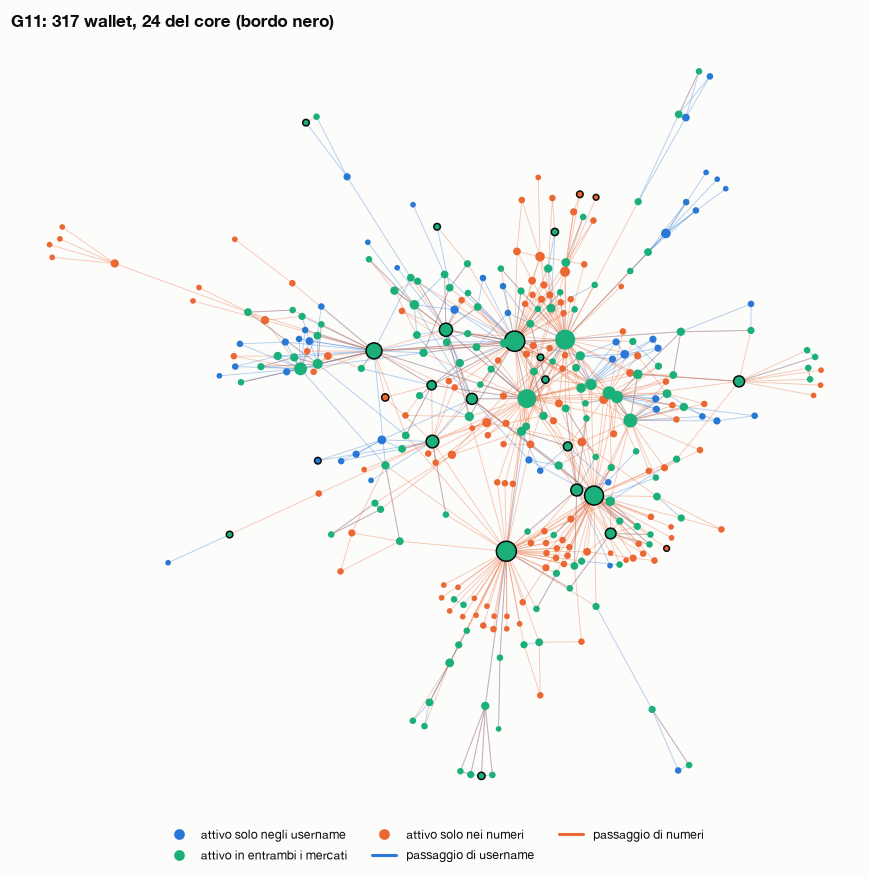

{'entrambi': 147, 'numeri': 123, 'username': 47}


In [9]:
import random
from matplotlib.lines import Line2D
ESEMPIO = 'G11'
c = GRANDI.index[GRANDI.gruppo == ESEMPIO][0]
E = pd.concat([ARCHI[l].loc[(ARCHI[l].ca == c) & (ARCHI[l].cb == c), ['wa', 'wb']].assign(layer=l) for l in LAYERS])
v = pd.Index(pd.unique(np.concatenate([E.wa, E.wb])))
att_l = {l: set(E.loc[E.layer == l, 'wa']) | set(E.loc[E.layer == l, 'wb']) for l in LAYERS}
tipo = np.where(v.isin(list(att_l[A] & att_l[B])), 'entrambi', np.where(v.isin(list(att_l[A])), 'username', 'numeri'))
h = ig.Graph(n=len(v), edges=np.c_[v.get_indexer(E.wa), v.get_indexer(E.wb)].tolist())
h.simplify()
ig.set_random_number_generator(random.Random(SEED))
pos = np.array(h.layout_fruchterman_reingold(niter=1500).coords)
grado_g = np.array(h.degree())
fig, ax = plt.subplots(figsize=(8, 8))
for l in LAYERS:
    x = E[E.layer == l]
    for a, b in zip(v.get_indexer(x.wa), v.get_indexer(x.wb)):
        ax.plot(pos[[a, b], 0], pos[[a, b], 1], color=COLORI[l], alpha=0.35, linewidth=0.6, zorder=1)
col = {'username': COLORI[A], 'numeri': COLORI[B], 'entrambi': COLORI['cross']}
for t in col:
    m = tipo == t
    ax.scatter(pos[m, 0], pos[m, 1], s=8 + 6 * np.sqrt(grado_g[m]) ** 1.6, color=col[t],
               edgecolors=np.where(v[m].isin(list(CORE)), INK, 'none'), linewidths=1.0, zorder=2)
ax.set_axis_off()
ax.set_title(f'{ESEMPIO}: {len(v)} wallet, {int(v.isin(list(CORE)).sum())} del core (bordo nero)')
voci = [Line2D([], [], marker='o', ls='', color=col['username'], label='attivo solo negli username'),
        Line2D([], [], marker='o', ls='', color=col['entrambi'], label='attivo in entrambi i mercati'),
        Line2D([], [], marker='o', ls='', color=col['numeri'], label='attivo solo nei numeri'),
        Line2D([], [], color=COLORI[A], label='passaggio di username'), Line2D([], [], color=COLORI[B], label='passaggio di numeri')]
ax.legend(handles=voci, loc='lower center', bbox_to_anchor=(0.5, -0.08), ncol=3, fontsize=8)
fig.tight_layout()
salva_figura(fig, 'd_multilayer_esempio')
plt.show()
print(pd.Series(tipo).value_counts().to_dict())

### Username e numeri insieme: le categorie che vanno in coppia

Sui gruppi grandi con almeno 20 wallet e almeno 20 NFT scambiati in ogni mercato:
* **rari con rari**: i gruppi con più username rari hanno anche più numeri rari? (Spearman tra le due quote);
* **coppie di categorie**: per ogni categoria di username e ogni categoria di numeri (categorie con almeno 200 NFT nel mercato, presenti in almeno 5 gruppi, `No_Categories` esclusa), Spearman tra i loro arricchimenti nei gruppi. Un valore alto vuol dire che i gruppi ricchi di quella categoria di username sono ricchi anche di quella categoria di numeri.

È una relazione tra gruppi, non tra wallet: non dice che lo stesso wallet abbia entrambi gli NFT. Le coppie non sono indipendenti tra loro, perché molte categorie di pregio si muovono insieme; il confronto con le coppie attese per caso (p < 0,01) è solo indicativo.

39 gruppi | rari con rari: Spearman 0.39 | coppie di categorie: 288, con p < 0,01: 41 (per caso circa 3)


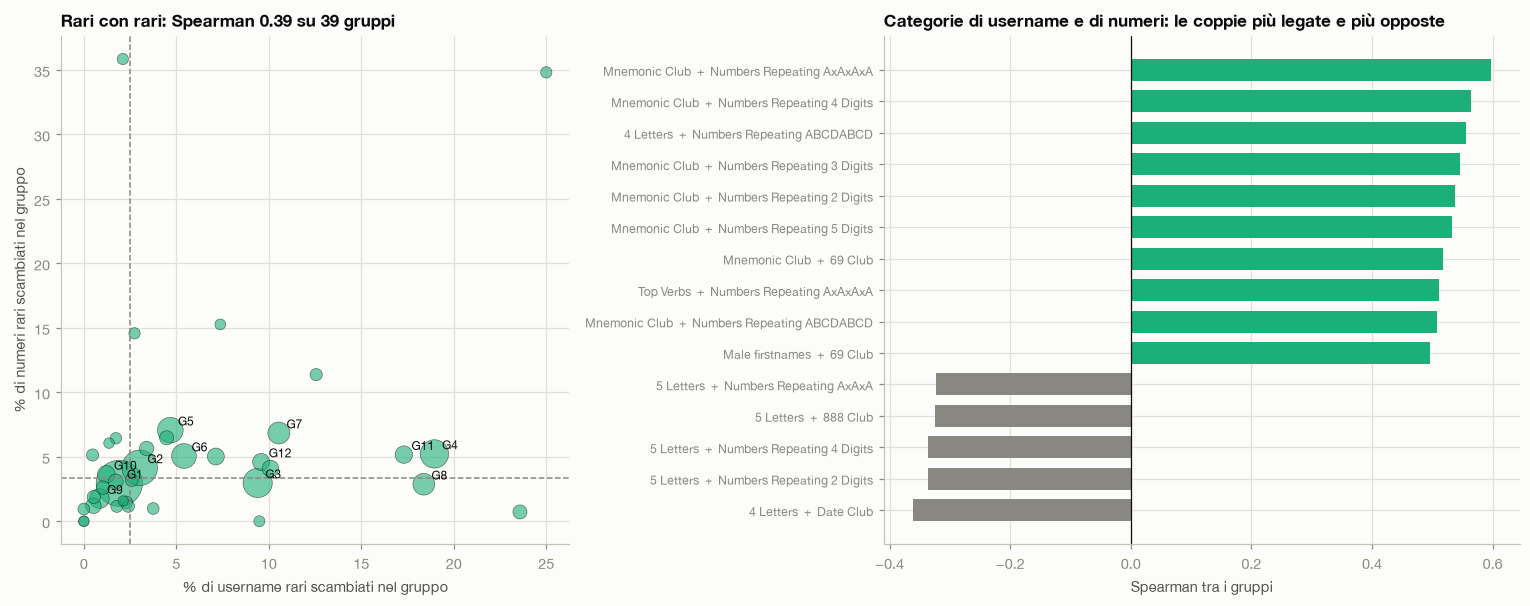

In [10]:
MIN_WALLET_COPPIE, MIN_NFT_COPPIE = 20, 20
uniche = dentro.drop_duplicates(['ca', 'layer', 'nft']).copy()
uniche['raro'] = [base_rari[l].get(n, False) for l, n in zip(uniche.layer, uniche.nft)]
R = uniche.groupby(['ca', 'layer']).agg(nft=('nft', 'size'), rari=('raro', 'mean')).unstack('layer')
scelti = [c for c in R.index if R.loc[c, ('nft', A)] >= MIN_NFT_COPPIE and R.loc[c, ('nft', B)] >= MIN_NFT_COPPIE and GRANDI.wallet[c] >= MIN_WALLET_COPPIE]
rho_rari = stats.spearmanr(R.loc[scelti, ('rari', A)], R.loc[scelti, ('rari', B)])

esplosa = uniche[uniche.ca.isin(scelti)].join(CAT, on='nft').explode('categories')
arr = {}
for l in LAYERS:
    q_base = CAT.reindex(pd.Index(PASS.loc[PASS.layer == l, 'nft'].unique())).explode().value_counts()
    n_base = PASS.loc[PASS.layer == l, 'nft'].nunique()
    conta = esplosa[esplosa.layer == l].groupby(['ca', 'categories']).nft.nunique().unstack(fill_value=0)
    quota = conta.div(uniche[(uniche.layer == l) & uniche.ca.isin(scelti)].groupby('ca').size(), axis=0)
    cats = [c for c in quota.columns if q_base.get(c, 0) >= MIN_NFT_CAT and (conta[c] > 0).sum() >= 5 and c != 'No_Categories']
    arr[l] = np.log2((quota[cats] / (q_base[cats] / n_base)).clip(lower=1 / 8)).clip(upper=8).reindex(scelti)
COPPIE = pd.DataFrame([{'username': cu, 'numeri': cn, **dict(zip(['rho', 'p'], stats.spearmanr(arr[A][cu], arr[B][cn])))}
                       for cu in arr[A] for cn in arr[B]]).sort_values('rho', ascending=False)
salva_tabella(COPPIE, 'd_multilayer_coppie_categorie', index=False)
print(f'{len(scelti)} gruppi | rari con rari: Spearman {rho_rari.statistic:.2f} | coppie di categorie: {len(COPPIE)}, '
      f'con p < 0,01: {(COPPIE.p < 0.01).sum()} (per caso circa {0.01 * len(COPPIE):.0f})')

fig, axes = plt.subplots(1, 2, figsize=(14, 5.6), gridspec_kw={'width_ratios': [1, 1.25]})
ax = axes[0]
xs, ys = R.loc[scelti, ('rari', A)] * 100, R.loc[scelti, ('rari', B)] * 100
ax.scatter(xs, ys, s=15 + 900 * np.sqrt(GRANDI.wallet[scelti] / GRANDI.wallet.max()), color=COLORI['cross'], alpha=0.6, edgecolors=INK, linewidths=0.4)
for c in scelti:
    if nome_g[c] in ordine_g:
        ax.annotate(nome_g[c], (xs[c], ys[c]), xytext=(5, 3), textcoords='offset points', fontsize=8)
ax.axvline(base_rari[A].mean() * 100, color=GRIGIO, linestyle='--', linewidth=1)
ax.axhline(base_rari[B].mean() * 100, color=GRIGIO, linestyle='--', linewidth=1)
ax.set_xlabel('% di username rari scambiati nel gruppo')
ax.set_ylabel('% di numeri rari scambiati nel gruppo')
ax.set_title(f'Rari con rari: Spearman {rho_rari.statistic:.2f} su {len(scelti)} gruppi')
ax = axes[1]
mostra = pd.concat([COPPIE.head(10), COPPIE.tail(5)])
y = np.arange(len(mostra))[::-1]
ax.barh(y, mostra.rho, color=np.where(mostra.rho > 0, COLORI['cross'], GRIGIO), height=0.7)
ax.set_yticks(y, [f'{u}  +  {n}' for u, n in zip(mostra.username, mostra.numeri)], fontsize=8)
ax.axvline(0, color=INK, linewidth=0.8)
ax.set_xlabel('Spearman tra i gruppi')
ax.set_title('Categorie di username e di numeri: le coppie più legate e più opposte')
fig.tight_layout()
salva_figura(fig, 'd_multilayer_coppie_categorie')
plt.show()

## 5. Cosa passa tra i gruppi grandi

Passaggi tra due gruppi grandi diversi, in ogni mercato. Due domande: quanta parte dei passaggi di un gruppo esce verso altre comunità, e se due gruppi che si scambiano username si scambiano anche numeri (correlazione di Spearman sulle coppie di gruppi collegate in almeno un mercato).

In [11]:
tocca = PASS[PASS.ca.isin(GRANDI.index) | PASS.cb.isin(GRANDI.index)]
uscita = {}
for l in LAYERS:
    x = tocca[tocca.layer == l]
    tot_g = pd.concat([x.ca, x.cb[x.ca != x.cb]]).value_counts()
    fuori = pd.concat([x.ca[x.ca != x.cb], x.cb[x.ca != x.cb]]).value_counts()
    uscita[f'quota verso altre comunità, {NOME[l].lower()}'] = (fuori / tot_g).reindex(GRANDI.index)
USCITA = pd.DataFrame(uscita).set_axis(GRANDI.gruppo)
tra = PASS[(PASS.ca != PASS.cb) & PASS.ca.isin(GRANDI.index) & PASS.cb.isin(GRANDI.index)]
tra = tra.assign(g1=np.minimum(tra.ca, tra.cb), g2=np.maximum(tra.ca, tra.cb))
flussi = tra.pivot_table(index=['g1', 'g2'], columns='layer', values='nft', aggfunc='size', fill_value=0).reindex(columns=LAYERS, fill_value=0)
rho = stats.spearmanr(flussi[A], flussi[B])
entrambi = ((flussi[A] > 0) & (flussi[B] > 0)).sum()
print(f'coppie di gruppi grandi collegate: {len(flussi):,} | in entrambi i mercati: {entrambi:,} | '
      f'Spearman tra passaggi di username e di numeri: {rho.statistic:.2f}'.replace(',', '.'))
display(USCITA.describe().loc[['50%', 'mean', 'max']].rename(index={'50%': 'mediana', 'mean': 'media'}))
flussi.assign(gruppo_1=lambda d: d.index.get_level_values(0).map(nome_g), gruppo_2=lambda d: d.index.get_level_values(1).map(nome_g)) \
      .reset_index(drop=True).rename(columns={l: f'passaggi {NOME[l].lower()}' for l in LAYERS}) \
      .to_csv(TABELLE / 'd_multilayer_flussi.csv', index=False)
print(f'tempo totale: {time.time() - t0:.0f} s')

coppie di gruppi grandi collegate: 259 | in entrambi i mercati: 128 | Spearman tra passaggi di username e di numeri: 0.47


,"quota verso altre comunità, username","quota verso altre comunità, numeri"
mediana,0.04957,0.06543
media,0.07955,0.07985
max,0.6667,0.2706


tempo totale: 481 s


## 6. Lettura

Rete senza contratti: 36.846 comunità sovrapposte.

* **Un wallet in più comunità.** 81.091 wallet stanno in più di una comunità: tutti i 234 del core (mediana 7), il 93% degli hub specialisti (mediana 4) e il 19% degli altri wallet. La sovrapposizione riguarda soprattutto i wallet importanti.
* **Tipi di comunità.** 25.785 comunità sono solo username e 5.627 solo numeri. Le inter-layer sono di due tipi: 5.079 con gli **stessi wallet** nei due mercati, quasi tutte piccole (2.672 coppie, la più grande ha 55 wallet), e 355 con **wallet diversi**, i gruppi grandi. Le 74 comunità speculari trovate confrontando le partizioni della fase C ricompaiono quasi tutte tra quelle con gli stessi wallet (72 su 74).
* **I gruppi grandi.** 355 comunità con 41.857 wallet, che contengono 228 dei 234 wallet del core e raccolgono il 15% dei passaggi interni degli username e il 41% di quelli dei numeri. In 9 dei 12 più grandi oltre il 75% dei passaggi interni tocca un wallet attivo in entrambi i mercati: sono questi ponti a tenere insieme la parte di username e quella di numeri.
* **Due tipi di gruppi grandi:**
  - **mercato aperto** (G1, G2, G9): molti wallet, la maggior parte dei passaggi interni sono vendite (G1 69% / 63%, G2 55% / 90%), username a prezzi mediani bassi (7-8 TON) e categorie vicine a quelle del mercato. G1, con 19.236 wallet, 139 del core e 1.440 hub specialisti, è il centro del commercio dei due mercati;
  - **asset di pregio senza vendite** (G3-G8, G10-G12): da circa 300 a 3.000 wallet, quasi nessuna vendita interna (dall'1% al 15%) e NFT rari in **entrambi** i mercati: username di 4 lettere da 3 a 17 volte più frequenti che nel mercato, numeri con cifre ripetute (ABCDABCD, 4-6 cifre uguali) da 2 a 8 volte. Quando questi numeri vengono venduti, il prezzo mediano va da 140 a 3.200 TON. Contengono molti wallet del core (fino a 88 in G3).
* **La mappa.** Su 42 gruppi grandi con almeno 20 wallet, 22 vendono meno della media del mercato (24% dei passaggi) e si scambiano più NFT rari della media (2,7%), fino al 33%: sono le reti di pregio. Il mercato aperto è fatto di pochi gruppi molto grandi a destra (G1, G2).
* **Il pregio va con il pregio.** Sui gruppi con abbastanza NFT in entrambi i mercati, quelli con più username rari hanno anche più numeri rari. Le categorie che vanno più spesso in coppia sono parole di dizionario con numeri a cifre ripetute, username di 4 lettere con numeri ABCDABCD, nomi di persona con 69 Club; gli username di 5 lettere, i più comuni, vanno invece con meno numeri ripetuti. I gruppi non si specializzano in un tema comune ai due mercati, ma in un livello di qualità (valori in `d_multilayer_coppie_categorie`).
* **Cosa si scambiano insieme.** Nei gruppi di pregio gli username rari vanno con i numeri rari: lo stesso gruppo di wallet si passa entrambi, quasi sempre senza prezzo. Tra un gruppo grande e l'altro passa poco: in mediana il 5% / 7% dei passaggi esce dal gruppo. Delle 259 coppie di gruppi grandi collegate, 128 si scambiano sia username sia numeri, e i due flussi vanno insieme (Spearman 0,47).
* **Limiti.** Parametri scelti: risoluzione 1, peso uguale ai due mercati, controparti sparse divise per mercato, soglie del 92% e del 50%. Manca una prova con un altro seed. Un passaggio senza prezzo non vuol dire regalo: nei gruppi di pregio può essere uno spostamento tra wallet dello stesso proprietario o un accordo pagato fuori dalla blockchain.